# D5 – Mini-projet : une série temporelle

**Python numérique – devoir n° 5 – à rendre pour le dimanche 18 octobre 2026, 23 h 59** (la séance 6 est le mardi 20)

Bienvenue dans votre cinquième devoir ! Nous allons y mettre en œuvre les notions vues en séance 5 : `to_datetime`, `DatetimeIndex`, la sélection par dates, `resample`, `rolling`, `df.plot` et les figures à plusieurs sous-graphiques avec `matplotlib`. C'est aussi un mini-projet : la dernière partie est ouverte, et c'est vous qui choisissez la question à laquelle répondre.

Durée indicative : 1 h 30.

````{admonition} Consignes de rendu
:class: important

* Ce notebook reste dans le dossier `D5/` de votre dépôt `pe-homework` (celui que le zip du sujet a créé en se dézippant), avec ses figures à côté, puis il doit être **commité et poussé** (`git add`, `git commit`, `git push`) avant la deadline. Attention, c'est la **date du commit** qui fait foi, pas celle du push ; le nom du fichier, lui, n'a pas d'importance (`sujet.ipynb` convient très bien). Le dossier `data/` livré avec le sujet reste lui aussi dans `D5/` : `git add D5` embarque tout le dossier, et c'est très bien ainsi (il ne pèse que quelques kilo-octets).
* Juste avant de rendre, **pensez à ré-exécuter toutes les cellules** via *Kernel → Restart Kernel and Run All Cells* : toutes doivent s'exécuter dans l'ordre et sans erreur. En effet, un notebook qui plante à mi-chemin sera corrigé jusqu'à l'erreur…
* Le notebook lit les données dans `data/comptage-velos.csv` (chemin relatif) ; la figure `serie.png` est quant à elle écrite dans le dossier du notebook.
* Les cellules `# votre code` sont à compléter ; vous pouvez ajouter autant de cellules que vous le souhaitez. Les cellules de test (`assert`) sont là pour vous aider : si elles passent sans erreur, c'est bon signe. Ne les modifiez pas !
* Répondez aux questions "en français" dans une cellule *Markdown*, en deux ou trois phrases. Dans ce devoir, la rédaction compte autant que le code.
````

````{admonition} Ce qui est autorisé
:class: note

* La documentation de `pandas` / `matplotlib`, les notebooks du cours, vos notes.
* Les assistants IA sont tolérés, avec la règle habituelle : **vous devez être capable d'expliquer chaque ligne que vous rendez**, et je pourrai vous demander de le faire à l'oral en séance. Le devoir est individuel.
* En revanche, pas de boucle `for` sur les lignes de la série : tout se fait avec les opérations `pandas`.
````

````{admonition} Les données
:class: warning

`data/comptage-velos.csv` contient le nombre de vélos comptés chaque jour par un compteur automatique installé sur une piste cyclable parisienne, du 1er janvier 2023 au 31 décembre 2024 : une colonne `date` (texte `AAAA-MM-JJ`) et une colonne `comptage`, séparées par `;`.

Attention, **ces données sont simulées** : je les ai produites avec le script `data/generate.py`, en fixant la graine afin que tout le monde travaille sur les mêmes valeurs. Vous pouvez le lire, mais seulement *après* avoir fait le devoir ! Elles ont cependant l'allure de vraies données de comptage, défauts compris : le fichier n'est pas trié, certaines lignes sont en double, certains jours n'ont pas de mesure, et le capteur a eu au moins deux ratés. Ainsi, comme dans la vraie vie, vous allez d'abord nettoyer, puis analyser.
````

## Barème

| Exercice | Contenu | Points |
|---|---|---|
| 1 | Chargement, index temporel, diagnostic et nettoyage | 6 |
| 2 | Rééchantillonnage (`resample`) et lissage (`rolling`) | 4 |
| 3 | Profils hebdomadaire et mensuel, 2023 vs 2024 | 4 |
| 4 | Figure à deux sous-graphiques `serie.png` | 3 |
| 5 | Question ouverte : une question, une figure, trois lignes de conclusion | 3 |
| **Total** | | **20** |
| Bonus | Jour le plus creux, croissance annuelle | +2 |

*Inspiré des exercices de <https://numerique-exos.info-mines.paris>.*

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Exercice 1 – Charger, indexer, nettoyer (6 pts)

**1.a** Lisez le fichier dans une `DataFrame` `df` et affichez `df.info()`. Quel est le type de la colonne `date` ? Pourquoi n'est-ce pas satisfaisant ? Le fichier est-il trié par date ?

In [2]:
# votre code
df = pd.read_csv('data/comptage-velos.csv',sep=';')
df.info()
df.tail()

<class 'pandas.DataFrame'>
RangeIndex: 734 entries, 0 to 733
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   date      734 non-null    str    
 1   comptage  726 non-null    float64
dtypes: float64(1), str(1)
memory usage: 18.8 KB


,date,comptage
729,2024-12-30,1900.0
730,2024-12-31,2126.0
731,2023-12-21,1960.0
732,2023-05-25,3101.0
733,2024-02-27,2622.0


Date est de type string, ce qui n'est pas pratique pour travailler avec (le trier, calcul de durées, etc). Il n'est pas trié par ailleurs comme le montre l'affichage de la fin du document.

In [3]:
assert df.shape == (734, 2)
assert list(df.columns) == ["date", "comptage"]
print("ok")

ok


**1.b** Construisez maintenant la `Series` `brut` : les comptages indexés par la date, avec un vrai `DatetimeIndex`, triée par date et en flottants.

In [4]:
# votre code
brut = df.set_index( pd.to_datetime(df["date"] ))["comptage"]
brut = brut.astype(float).sort_index()

In [5]:
assert isinstance(brut, pd.Series)
assert isinstance(brut.index, pd.DatetimeIndex)
assert brut.index.is_monotonic_increasing
assert len(brut) == 734
assert brut.index[0] == pd.Timestamp("2023-01-01") and brut.index[-1] == pd.Timestamp("2024-12-31")
print("ok")

ok


````{admonition} Pas encore vu en cours : duplicated()
:class: note

`serie.duplicated()` — ou `index.duplicated()` — renvoie un tableau de booléens de même longueur, avec `True` sur les valeurs *déjà rencontrées plus haut* : la première occurrence vaut `False`, les suivantes `True`. Ainsi, sur `[3, 1, 3, 3]`, on obtient `[False, False, True, True]`. Combiné à `~`, il permet donc de ne garder que la première occurrence de chaque valeur.
````

**1.c** Place au diagnostic. Répondez d'abord par du code, puis résumez vos observations dans une cellule Markdown :

* combien de dates apparaissent en double ? lesquelles ?
* combien de valeurs manquantes ? quels jours ?
* observez `brut.describe()` : le minimum et le maximum vous semblent-ils plausibles pour un compteur vélo ? Affichez les jours dont le comptage est nul, et ceux dont le comptage dépasse 3 fois la médiane.

In [6]:
# votre code
nb_double = brut.index.duplicated().sum()
positions_manquantes = df.loc[brut.index.duplicated()]['date']
print('nombre jours manquants : ',nb_double, positions_manquantes)

val_manquantes = brut.isna().sum()
jours = brut.index[brut.isna()]
print('nombre valeurs manquantes : ',val_manquantes, jours)

brut.describe()
jours_nul = brut.index[brut == 0]
jours_3 = brut.index[brut > 3*brut.median()]
print(jours_nul,jours_3)

nombre jours manquants :  3 145    2023-05-26
356    2023-06-06
425    2024-03-01
Name: date, dtype: str
nombre valeurs manquantes :  8 DatetimeIndex(['2023-02-23', '2023-06-25', '2023-12-01', '2024-01-09',
               '2024-02-08', '2024-03-13', '2024-11-17', '2024-11-22'],
              dtype='datetime64[us]', name='date', freq=None)
DatetimeIndex(['2024-06-27'], dtype='datetime64[us]', name='date', freq=None) DatetimeIndex(['2024-07-04'], dtype='datetime64[us]', name='date', freq=None)


En conclusion, il y a 3 dates en double et 8 valeurs manquantes. Le maximum et le minimun semblent peu plausibles, on peu éliminer directement 2 valeurs aberantes (compte à 0 et supérieur à 3 fois la médiane).

In [7]:
assert brut.index.duplicated().sum() == 3
assert brut.isna().sum() == 8
assert (brut == 0).sum() == 1
assert (brut > 3 * brut.median()).sum() == 1
print("ok")

ok


````{admonition} Pas encore vu en cours : interpolate()
:class: note

`serie.interpolate()` remplace chaque `NaN` par une valeur déduite de ses voisins non manquants, par interpolation linéaire par défaut : sur `[10, NaN, NaN, 40]`, on obtient `[10, 20, 30, 40]`. C'est l'alternative à `fillna` quand les données ont un ordre naturel, comme ici le temps.
````

**1.d** Passons au nettoyage. Construisez la série propre `velos`, en trois temps :

1. supprimez les doublons d'index en ne gardant que la première occurrence (`duplicated()`) ;
2. remplacez les deux valeurs aberrantes (comptage nul ou supérieur à 3 fois la médiane) par `NaN` ;
3. remplissez tous les `NaN` (les 8 jours vides + les 2 aberrants) par interpolation linéaire.

Vérifiez enfin que `velos` a exactement une valeur par jour du 1er janvier 2023 au 31 décembre 2024 (soit 731 jours), et plus aucun `NaN`.

In [8]:
# votre code
velos = brut[~brut.index.duplicated()].copy()
velos.loc[jours_nul] = np.nan
velos.loc[jours_3] = np.nan
velos.interpolate(inplace=True)
#test de vérif
assert velos.isna().sum() == 0
assert len(velos) == 731
assert not (velos.index.duplicated().any())

In [9]:
assert len(velos) == 731
assert velos.isna().sum() == 0
assert not velos.index.duplicated().any()
assert (velos.index == pd.date_range("2023-01-01", "2024-12-31", freq="D")).all()
assert velos.min() > 100 and velos.max() < 6000
assert abs(velos.loc["2024-07-04"] - (velos.loc["2024-07-03"] + velos.loc["2024-07-05"]) / 2) < 1
print("ok")

ok


## Exercice 2 – Rééchantillonner et lisser (4 pts)

**2.a** Calculez :

* `hebdo` : la moyenne par semaine ;
* `mensuel` : la moyenne par mois (l'alias de fréquence des mois est `"ME"`, *month end*, depuis pandas 2.2 ; `"M"` si votre pandas est plus ancien) ;
* `annuel` : le **total** par année.

Combien de lignes ont `hebdo` et `mensuel` ? Pourquoi `hebdo` n'a-t-il pas exactement 731 / 7 lignes ?

In [10]:
# votre code
hebdo = velos.resample("W").mean()
mensuel = velos.resample("ME").mean()
annuel = velos.resample("YE").sum()
print(len(hebdo),len(mensuel))


106 24


Le resample semble travailler sur les semaines du calendrier et non par bloc de 7 jours.

In [11]:
assert len(hebdo) == 106 and len(mensuel) == 24 and len(annuel) == 2
assert abs(mensuel.sum() * 30.4 - velos.sum()) / velos.sum() < 0.05
assert annuel.iloc[1] > annuel.iloc[0]
print("ok")

ok


**2.b** Calculez `lisse`, la moyenne glissante **centrée** sur 7 jours. Combien de `NaN` contient-elle, et où ? Pourquoi 7 jours est-il un bon choix de fenêtre pour cette série ? Enfin, tracez `velos` (trait fin, transparent) et `lisse` sur le même graphique, avec la méthode `.plot()` des `Series`.

6 DatetimeIndex(['2023-01-01', '2023-01-02', '2023-01-03', '2024-12-29',
               '2024-12-30', '2024-12-31'],
              dtype='datetime64[us]', name='date', freq=None)


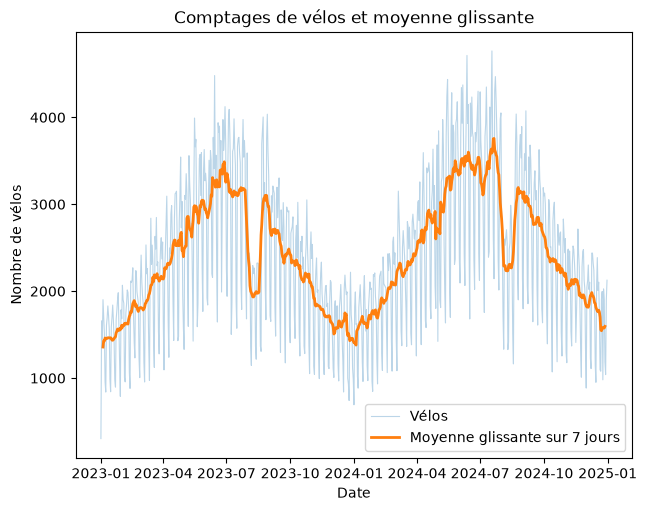

In [12]:
# votre code
lisse = velos.rolling(window=7, center=True).mean()
nb_na = lisse.isna().sum()
jours_manquants = velos.index[lisse.isna()]
print(nb_na,jours_manquants)
plt.plot(velos.index,velos,alpha=0.3, linewidth=0.8, label="Vélos")
plt.plot(lisse.index, lisse,linewidth=2, label="Moyenne glissante sur 7 jours")
plt.tight_layout()
plt.xlabel("Date")
plt.ylabel("Nombre de vélos")
plt.title("Comptages de vélos et moyenne glissante")
plt.legend()
plt.show()

On a 6 valeurs manquantes, au tout début et à la fin (la où les semaines ne sont pas completes). On peut s'attendre au fait que les habitudes varient en fonction du weekend ou de la semaine, d'ou avec 7 jours le moyennage est pertinent.

In [13]:
assert len(lisse) == 731
assert lisse.isna().sum() == 6
assert abs(lisse.loc["2023-06-15"] - velos.loc["2023-06-12":"2023-06-18"].mean()) < 1e-9
print("ok")

ok


## Exercice 3 – Profils (4 pts)

**3.a** Commençons par le profil hebdomadaire : calculez `profil_semaine`, la moyenne des comptages pour chaque jour de la semaine, avec 0 = lundi … 6 = dimanche. Remplacez ensuite l'index `0..6` par les noms des jours (`"lun"`, `"mar"`, … `"dim"`). De combien (en %) le dimanche est-il plus bas que la moyenne des jours de semaine (lundi à vendredi) ?

In [14]:
# votre code
profil_semaine = velos.groupby(velos.index.dayofweek).mean()
profil_semaine.index = ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
moyenne_semaine = profil_semaine.loc[["lun", "mar", "mer", "jeu", "ven"]].mean()
baisse_dimanche = (moyenne_semaine-profil_semaine.loc["dim"])/moyenne_semaine * 100

print(profil_semaine)
print("baisse du dimanche", baisse_dimanche)

lun    2694.095238
mar    2868.504762
mer    2877.658654
jeu    2782.269231
ven    2595.394231
sam    1639.942308
dim    1386.380952
Name: comptage, dtype: float64
baisse du dimanche 49.83395691464415


In [15]:
assert profil_semaine.shape == (7,)
assert list(profil_semaine.index) == ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
assert profil_semaine["sam"] < 0.75 * profil_semaine["lun"]
assert profil_semaine["dim"] < profil_semaine["sam"]
print("ok")

ok


````{admonition} Pas encore vu en cours : idxmax et idxmin
:class: note

`serie.idxmax()` renvoie l'**étiquette** de la plus grande valeur (ici un numéro de mois), alors que `serie.max()` renvoie la valeur elle-même ; `idxmin` fait de même pour la plus petite. Sur une série indexée par des dates, on récupère donc directement le `Timestamp` du maximum.
````

**3.b** Intéressons-nous maintenant à la saisonnalité : calculez `profil_mois`, la moyenne pour chaque mois de l'année (1 à 12), les deux années confondues. Quel est le mois le plus chargé ? Et que se passe-t-il en août ?

In [16]:
# votre code
profil_mois = velos.groupby(velos.index.month).mean()
maxi = profil_mois.idxmax()
print(profil_mois)
print(maxi)

date
1     1547.806452
2     1845.000000
3     2144.024194
4     2585.300000
5     3013.000000
6     3313.183333
7     3285.483871
8     2535.774194
9     2693.766667
10    2309.419355
11    1924.308333
12    1657.911290
Name: comptage, dtype: float64
6


C'est juin le mois le plus chargé. On à une fort baisse en aout surement du aux vacances ;)

In [17]:
assert profil_mois.shape == (12,) and list(profil_mois.index) == list(range(1, 13))
assert profil_mois.idxmax() in (6, 7)
assert profil_mois[8] < profil_mois[7] and profil_mois[8] < profil_mois[9]
assert profil_mois.idxmin() in (1, 12)
print("ok")

ok


**3.c** Opposons enfin 2023 à 2024 : avec la sélection par chaîne de date, calculez la moyenne journalière de chaque année, puis la croissance en % de 2023 à 2024 (variable `croissance`). Posez-vous ensuite la même question mois par mois : construisez la table `par_mois` de forme `(12, 2)` (lignes = mois, colonnes = années) — `unstack` peut aider — et repérez le mois où la progression a été la plus forte.

In [18]:
# votre code
par_année = velos.groupby(velos.index.year).mean()
croissance = (par_année.iloc[1]-par_année.iloc[0])/par_année.iloc[0]*100
print(par_année)
print(croissance)

par_mois = velos.groupby([velos.index.month, velos.index.year]).mean().unstack()
print(par_mois)
progression = (par_mois[2024] - par_mois[2023]) / par_mois[2023] * 100
print(progression)
print(progression.idxmax())

date
2023    2285.983562
2024    2525.591530
Name: comptage, dtype: float64
10.481613797717293
date         2023         2024
date                          
1     1451.612903  1644.000000
2     1755.160714  1931.741379
3     2053.516129  2234.532258
4     2393.466667  2777.133333
5     2849.903226  3176.096774
6     3223.133333  3403.233333
7     3091.870968  3479.096774
8     2454.193548  2617.354839
9     2537.033333  2850.500000
10    2232.225806  2386.612903
11    1816.400000  2032.216667
12    1548.564516  1767.258065
date
1     13.253333
2     10.060655
3      8.814936
4     16.029748
5     11.445776
6      5.587730
7     12.523996
8      6.648265
9     12.355638
10     6.916285
11    11.881561
12    14.122340
dtype: float64
4


Il s'agit donc d'avril.

In [19]:
assert 7 < croissance < 14
assert par_mois.shape == (12, 2)
assert list(par_mois.columns) == [2023, 2024]
assert (par_mois[2024] > par_mois[2023]).sum() >= 10
print("ok")

ok


## Exercice 4 – Figure à deux sous-graphiques (3 pts)

Construisez une figure `fig, (ax_haut, ax_bas) = plt.subplots(2, 1, figsize=(11, 8))` :

* en haut : la série journalière `velos` (trait fin, transparent) et la série lissée `lisse` (trait plus épais), avec une légende, un titre et un nom d'axe des ordonnées ;
* en bas : le profil hebdomadaire `profil_semaine` en barres, avec un titre et un nom d'axe des ordonnées.

Terminez par `fig.tight_layout()` et enregistrez dans `serie.png` (`fig.savefig`).

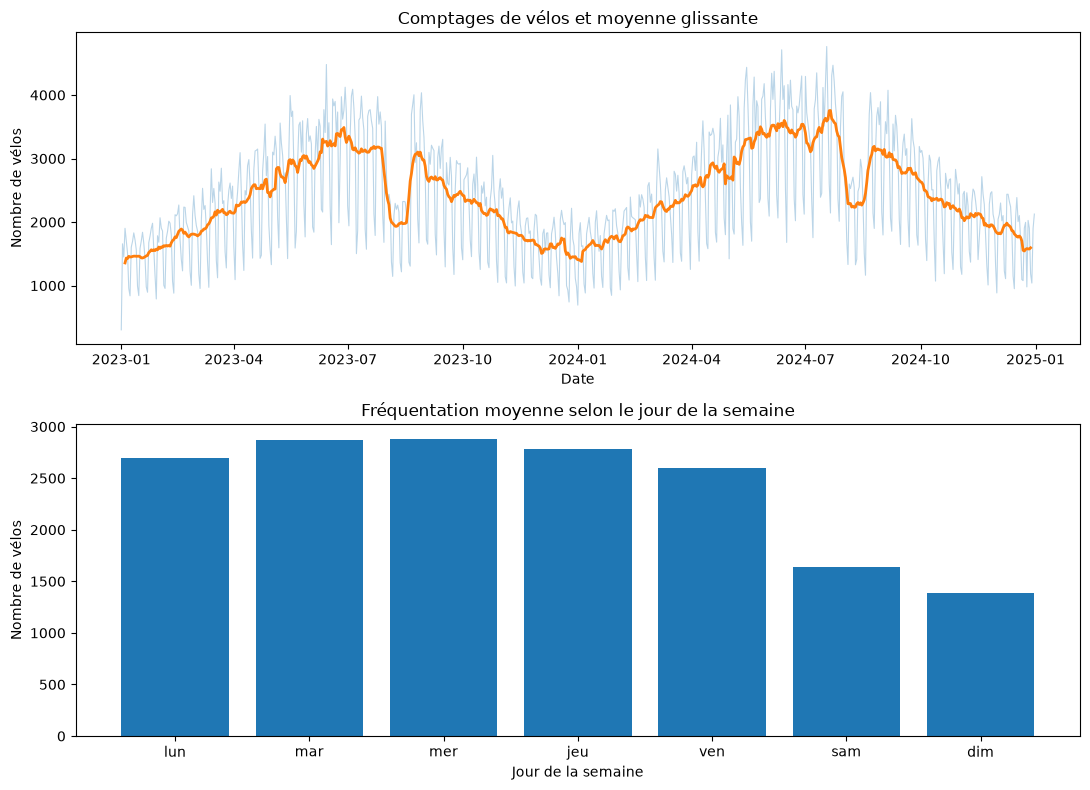

In [20]:
# votre code
fig, (ax_haut, ax_bas) = plt.subplots(2, 1, figsize=(11, 8))
ax_haut.plot(velos.index,velos,alpha=0.3, linewidth=0.8, label="Vélos")
ax_haut.plot(lisse.index, lisse,linewidth=2, label="Moyenne glissante sur 7 jours")
ax_haut.set_xlabel("Date")
ax_haut.set_ylabel("Nombre de vélos")
ax_haut.set_title("Comptages de vélos et moyenne glissante")

ax_bas.bar(profil_semaine.index , profil_semaine.values )
ax_bas.set_title("Fréquentation moyenne selon le jour de la semaine")
ax_bas.set_ylabel("Nombre de vélos")
ax_bas.set_xlabel("Jour de la semaine")

fig.tight_layout()
fig.savefig('serie.png')

In [21]:
assert os.path.exists("serie.png")
print("ok")

ok


## Exercice 5 – Question ouverte (3 pts)

C'est ici que vous prenez la main ! Choisissez **une** question sur cette série, puis répondez-y avec une figure (au moins une courbe ou un diagramme, légendée et titrée) et trois lignes de conclusion en Markdown. Voici quelques idées, mais une question à vous est la bienvenue :

* le creux d'août a-t-il la même ampleur en 2023 et en 2024 ?
* l'écart week-end / semaine est-il le même en été et en hiver ?
* quelle semaine de l'année est la plus chargée ? la plus creuse ? est-ce la même les deux années ?
* la croissance entre 2023 et 2024 est-elle uniforme sur l'année, ou concentrée sur certains mois ?
* que se passe-t-il autour des jours fériés que vous connaissez ?

Côté barème, je compte un point pour la pertinence de la méthode, un point pour une figure lisible et correcte, et un point pour une conclusion chiffrée et honnête.

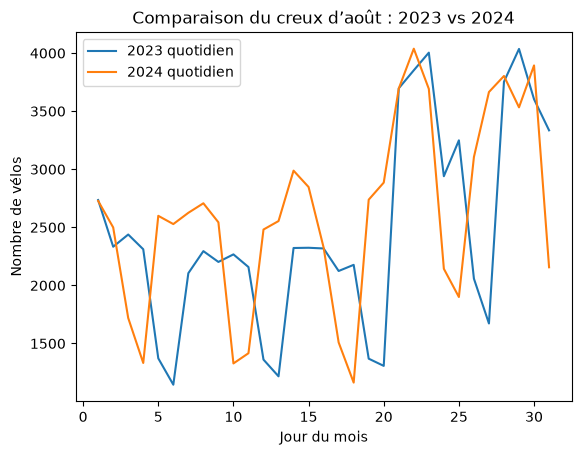

Moyenne 2023 : 2454
Moyenne 2024 : 2617
Variation 2023 : 26 %
Variation 2024 : 33 %


In [22]:
velos_2023 = velos.loc["2023-08"]
velos_2024 = velos.loc["2024-08"]

#on calcule les moyenne glisantes sur le mois d'aout
lisse_2023 = velos_2023.rolling(7, center=True).mean()
lisse_2024 = velos_2024.rolling(7, center=True).mean()


plt.plot(velos_2023.index.day,velos_2023,label="2023 quotidien")
plt.plot(velos_2024.index.day,velos_2024,label="2024 quotidien")



plt.title("Comparaison du creux d’août : 2023 vs 2024")
plt.xlabel("Jour du mois")
plt.ylabel("Nombre de vélos")
plt.legend()
plt.show()

moy_2023 = velos_2023.mean()
moy_2024 = velos_2024.mean()
print("Moyenne 2023 :",round(moy_2023))
print("Moyenne 2024 :",round(moy_2024))

variation_2023 = abs((moy_2023 - velos.loc["2023-07"].mean())/moy_2023)
variation_2024 = abs((moy_2024- velos.loc["2024-07"].mean())/moy_2024)
print("Variation 2023 :",round(variation_2023*100),"%")
print("Variation 2024 :",round(variation_2024*100),"%")

Comme illustré sur le graphique, la tendance ne saute pas aux yeux. Cela est confirmé par les moyennes très proches qui ont été calculées. On peut néamoins considérer que l'écart entre les variations relatives juillet et août pousse à répondre qu'il s'agit du mois d'août 2024 qui a connu le plus gros creux.

## Bonus (+2)

**Bo.1** Quel est le jour le plus creux de toute la série ? Et le plus chargé ? Pour chacun, donnez le jour de la semaine (`.day_name()`) et proposez une explication.

````{admonition} Pas encore vu en cours : pct_change
:class: note

`serie.pct_change()` renvoie la variation *relative* d'une valeur à la suivante : sur `[100, 110, 99]`, elle donne `[NaN, 0.10, -0.10]`. La première case vaut `NaN` faute de valeur précédente, et le résultat est une proportion, à multiplier par 100 pour l'exprimer en pourcentage.
````

**Bo.2** Calculez la croissance annuelle en % à partir des totaux annuels `annuel`. Pourquoi ce chiffre est-il légèrement différent de `croissance` (exercice 3.c) ?

In [23]:
# votre code

Bon courage à tous ! Pour toute question sur le sujet, écrivez-moi à [aurelien.noce@minesparis.psl.eu](mailto:aurelien.noce@minesparis.psl.eu), en mettant [aurelien.noce@imagine-app.fr](mailto:aurelien.noce@imagine-app.fr) en copie : la messagerie de l'école perd parfois des mails, la seconde adresse sert de filet.

Au plaisir de vous lire,

votre responsable de cours, Aurélien Noce